# 棋力預測 Baseline

這份 notebook 示範棋力預測子題的完整流程：從官方提供的 CSV 讀進棋譜，抽出特徵、
訓練模型，最後產出可直接上傳的 `submission_rank.csv`。

**這是參考實作，不是標準答案。** 模型架構、特徵設計、訓練方式都沒有限制，
歡迎自行修改。照本 notebook 跑完可以得到的分數列在最後一節，供你評估自己的改動
有沒有進步。

資料集與提交格式的正式定義以官方發佈為準，本 notebook 只補充「怎麼做」的部分。

## 任務

給定某位玩家的 5～20 局棋譜，預測這位玩家的棋力等級。等級由弱到強共 10 級：

```
D  C  B  A  1D  2D  3D  4D  5D  6D
```

## 環境需求

| 項目 | 需求 |
|---|---|
| GPU | 至少 9 GB VRAM（訓練約 8.6 GB，推論約 0.6 GB） |
| 磁碟 | 特徵約 1.7 GB，checkpoint 每個 101 MB |
| 套件 | torch、webdataset、sgfmill、pandas、numpy、matplotlib |

建議在具備 GPU 的 Linux 環境下執行。沒有 GPU 的話訓練時間會長到不切實際。

VRAM 不足時把 `BATCH_SIZE` 調小即可：128 約需 4.5 GB、64 約需 2.5 GB。
這只影響訓練速度與收斂步調，不影響流程能否跑通。

本 notebook 依賴 Linux 的 `fork` 啟動方式（多進程的 worker 函式定義在 notebook 內）。
在 macOS 或 Windows 上執行時，請把 `NPROC` 設為 1，或把相關函式移到獨立的 `.py`。

執行前請把下一格的路徑改成你自己的資料集位置。


In [1]:
import multiprocessing as mp
mp.set_start_method('fork', force=True)
import glob
import os
import time
from multiprocessing import Pool, Process

import numpy as np
import pandas as pd
import torch
import torch.optim as optim
import webdataset as wds

from torch.utils.data import DataLoader

from utils import SGFParseRankPrediction
from network import GoRankResNet  #', wds.__version__))

In [2]:
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

True NVIDIA GeForce RTX 4060 Laptop GPU


In [3]:
# 官方資料放置位置：training/ 與 tests/ 依官方發佈的結構擺放
TRAIN_DIR = './training'
TEST_DIR = './tests'
FEAT_DIR = './rank-features'
CKPT_DIR = './rank-trained-models'

# 等級由弱到強。順序很重要：評分時的「相鄰一級」就是這個順序上的相鄰。
LEVELS = ['D', 'C', 'B', 'A', '1D', '2D', '3D', '4D', '5D', '6D']
RANK_TO_ID = {lv: i for i, lv in enumerate(LEVELS)}
ID_TO_RANK = {i: lv for lv, i in RANK_TO_ID.items()}

NPROC = 8              # 特徵抽取的進程數，設成 CPU 核數
PER_SHARD = 1000       # 每個 webdataset 分片的樣本數
SEED = 42
VAL_SIZE = 100_000     # 從訓練集切出來的驗證集大小

BATCH_SIZE = 128
LEARNING_RATE = 1e-3
NUM_EPOCHS = 5
NUM_CLASSES = len(LEVELS)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.makedirs(CKPT_DIR, exist_ok=True)
print('device', DEVICE)
RANK_TO_ID

device cuda


{'D': 0,
 'C': 1,
 'B': 2,
 'A': 3,
 '1D': 4,
 '2D': 5,
 '3D': 6,
 '4D': 7,
 '5D': 8,
 '6D': 9}

# 0. Quick Look to the Dataset

訓練資料是每個等級一個 CSV，共 10 檔、各 10 萬局，總計 100 萬局，等級完全均衡。
欄位為 `player_id,game_id,rank,color,sgf_content`，本任務用得到的是 `sgf_content`
（棋譜）與 `rank`（預測目標）。

先全部讀進來，shuffle 之後切出驗證集。原資料已是等級均衡，shuffle 後各級在驗證集
的比例自然接近 1/10，不需要分層抽樣。

In [12]:

df = pd.concat([pd.read_csv(p) for p in sorted(glob.glob(f'{TRAIN_DIR}/train_*.csv'))],
               ignore_index=True)
df = df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
print('全量 %s 局' % format(len(df), ','))
print('等級分布', df['rank'].value_counts().to_dict())

df_val, df_train = df.iloc[:VAL_SIZE], df.iloc[VAL_SIZE:]
print('切分：訓練 %s / 驗證 %s' % (format(len(df_train), ','), format(len(df_val), ',')))
df.head(3)

全量 1,000,000 局
等級分布 {'D': 100000, '1D': 100000, '6D': 100000, '2D': 100000, 'B': 100000, '4D': 100000, '5D': 100000, 'C': 100000, 'A': 100000, '3D': 100000}
切分：訓練 900,000 / 驗證 100,000


,player_id,game_id,rank,color,sgf_content
0,1b2bf55b027076cb,g_0087232,D,W,(;SZ[19];B[pd];W[dp];B[pq];W[dd];B[po];W[nc];B...
1,61530f4acb43c55b,g_0079955,1D,W,(;SZ[19];B[pd];W[dp];B[pq];W[po];B[qo];W[qn];B...
2,418310e17516110f,g_0067131,6D,W,(;SZ[19];B[pd];W[dd];B[qp];W[dq];B[op];W[qf];B...


# 1. Feature Extraction

本節是**一次性作業**。分片產出後重跑訓練可以直接跳到第 2 節。

`SGFParseRankPrediction` 把一局棋譜轉成 `(500, 19, 19)` 的張量：取最後 250 個盤面，
每個盤面拆成黑子、白子兩個平面（250 × 2 = 500）。不足 250 手的棋局在前面補空盤。
輸出存成 `uint8` 省空間，訓練時再轉回 `float32`。

In [13]:
_parser = SGFParseRankPrediction()
_demo = df.iloc[0]['sgf_content']
_feat, _err = _parser.features_from_sgf_content(_demo)
print('一局棋的特徵形狀:', _feat.shape, _feat.dtype)

一局棋的特徵形狀: (500, 19, 19) uint8


### 存成 webdataset 分片

100 萬局的特徵不可能全部放進記憶體，必須落地。這裡用 webdataset 的分片格式，
訓練時串流讀取。有三個實作細節值得注意：

**分片存成 `.tar.gz`。** 特徵是二元遮罩，壓縮率約 70 倍 —— 不壓縮要 180 GB，
壓縮後訓練集 1.5 GB、驗證集 163 MB。`ShardWriter` 看到 `.gz` 副檔名會自動壓縮，
讀取端也自動解壓，程式碼不需要改。

**用多進程並行。** 單執行緒抽完 100 萬局相當耗時，切成多份可大幅縮短。
每個進程寫自己的分片範圍，彼此不共用寫入端。

**`__key__` 要加等級前綴。** `game_id` 只在單一等級的 CSV 內唯一 —— 每個檔案都各自
從 `g_0000001` 起編，跨檔會重複 10 次。webdataset 以 `__key__` 當 tar 內的檔名，
撞號會讓分片讀不回來。

In [14]:
def extract_worker(df_part, pattern, wid):
    """抽一份切片的特徵並寫成分片。每個進程獨立持有 parser 與 ShardWriter。"""
    parser = SGFParseRankPrediction()
    written = bad = 0
    t0 = time.time()
    with wds.ShardWriter(pattern, maxcount=PER_SHARD, verbose=0) as sink:
        for _, row in df_part.iterrows():
            feat, err = parser.features_from_sgf_content(row['sgf_content'])
            if err is not None:
                bad += 1
                continue
            sink.write({
                '__key__': '%s_%s' % (row['rank'], row['game_id']),
                'features.npy': feat,
                'label.txt': str(row['rank']),
                'rank_idx.txt': str(RANK_TO_ID[row['rank']]),
                'game_name.txt': str(row['game_id']),
            })
            written += 1
            if written % 20000 == 0:
                print('  [w%d] %d/%d  %.0f 分'
                      % (wid, written, len(df_part), (time.time() - t0) / 60),
                      flush=True)
    print('  [w%d] 寫入 %d 筆（解析失敗 %d）%.1f 分'
          % (wid, written, bad, (time.time() - t0) / 60), flush=True)


def extract_split(df_part, tag):
    """跑完一個 split，並確認產出真的有內容。"""
    outdir = f'{FEAT_DIR}/{tag}'
    os.makedirs(outdir, exist_ok=True)

    procs = []
    for i in range(NPROC):
        pat = '%s/%s-w%d-%%06d.tar.gz' % (outdir, tag, i)
        p = Process(target=extract_worker, args=(df_part.iloc[i::NPROC], pat, i))
        p.start()
        procs.append(p)
    for p in procs:
        p.join()
        if p.exitcode != 0:
            raise SystemExit('%s: worker 非正常結束（exitcode %s）' % (tag, p.exitcode))

    shards = glob.glob(f'{outdir}/*.tar.gz')
    total = sum(os.path.getsize(s) for s in shards)
    avg = total / len(shards) if shards else 0
    print('%s: %d 個分片, %.2f GB, 平均 %.1f KB/分片'
          % (tag, len(shards), total / 1e9, avg / 1024), flush=True)
    # 平均分片大小是最簡單的健全性檢查：寫入迴圈若出錯，計數器仍會累加、log 看起來
    # 正常，但 tar 是空的（gzip 後僅 46 bytes）。只數分片數量抓不到這種情況。
    if avg < 10 * 1024:
        raise SystemExit('%s: 分片平均僅 %.0f bytes，判定為空分片' % (tag, avg))

In [15]:
# 一次性作業。分片產出後重跑訓練可以直接從下一節開始。
t0 = time.time()
extract_split(df_val, 'val')
extract_split(df_train, 'train')
print('完成，總耗時 %.1f 分' % ((time.time() - t0) / 60))

  [w3] 寫入 12500 筆（解析失敗 0）4.7 分
  [w4] 寫入 12500 筆（解析失敗 0）4.7 分
  [w0] 寫入 12500 筆（解析失敗 0）4.7 分
  [w7] 寫入 12500 筆（解析失敗 0）4.7 分
  [w6] 寫入 12500 筆（解析失敗 0）4.7 分
  [w1] 寫入 12500 筆（解析失敗 0）4.7 分
  [w5] 寫入 12500 筆（解析失敗 0）4.7 分
  [w2] 寫入 12500 筆（解析失敗 0）4.8 分
val: 104 個分片, 0.17 GB, 平均 1591.7 KB/分片
  [w4] 20000/112500  7 分
  [w0] 20000/112500  8 分
  [w3] 20000/112500  8 分
  [w5] 20000/112500  8 分
  [w2] 20000/112500  8 分
  [w6] 20000/112500  8 分
  [w1] 20000/112500  8 分
  [w7] 20000/112500  8 分
  [w0] 40000/112500  15 分
  [w4] 40000/112500  15 分
  [w5] 40000/112500  15 分
  [w6] 40000/112500  15 分
  [w1] 40000/112500  15 分
  [w7] 40000/112500  15 分
  [w3] 40000/112500  15 分
  [w2] 40000/112500  15 分
  [w0] 60000/112500  23 分
  [w5] 60000/112500  23 分
  [w4] 60000/112500  23 分
  [w2] 60000/112500  23 分
  [w1] 60000/112500  23 分
  [w6] 60000/112500  23 分
  [w3] 60000/112500  23 分
  [w7] 60000/112500  23 分
  [w5] 80000/112500  30 分
  [w0] 80000/112500  30 分
  [w4] 80000/112500  30 分
  [w6] 80000/112500

# 2. Data Loader

**若已完成第 1 節的特徵抽取，可以直接從這裡開始。**

分片是 gzip，單執行緒解壓會拖住 GPU，所以要開多個 worker。但 `IterableDataset`
搭配多 worker 有個陷阱：若沒有正確切分，每個 worker 會各自跑完整份資料集，
一個 epoch 實際看到 N 倍資料而毫無徵兆。

這裡的做法是啟動時先數一遍驗證集的實際筆數，對不上就退回單執行緒。

In [16]:
def decode_sample(sample):
    return (torch.from_numpy(sample['features.npy']).float(),
            torch.tensor(int(sample['rank_idx.txt']), dtype=torch.long),
            sample['game_name.txt'])


def make_loader(shards, workers, shuffle):
    ds = wds.WebDataset(shards, shardshuffle=1 if shuffle else 0)
    if shuffle:
        ds = ds.shuffle(1000)
    ds = ds.decode().map(decode_sample).batched(BATCH_SIZE, partial=True)
    return DataLoader(ds, batch_size=None, num_workers=workers,
                      pin_memory=True, persistent_workers=workers > 0)


def pick_workers(val_shards, candidate=4):
    """數一遍驗證集：筆數對得上才用多 worker，否則退回單執行緒。"""
    total = sum(len(y) for _x, y, _n in make_loader(val_shards, candidate, False))
    if total == VAL_SIZE:
        print('num_workers=%d 驗證通過（%d 筆）' % (candidate, total))
        return candidate
    print('num_workers=%d 讀出 %d 筆（應為 %d），退回 0' % (candidate, total, VAL_SIZE))
    return 0

In [17]:
train_shards = sorted(glob.glob(f'{FEAT_DIR}/train/*.tar.gz'))
val_shards = sorted(glob.glob(f'{FEAT_DIR}/val/*.tar.gz'))
print('分片：train %d / val %d' % (len(train_shards), len(val_shards)))

workers = pick_workers(val_shards)
train_loader = make_loader(train_shards, workers, True)
val_loader = make_loader(val_shards, workers, False)

_x, _y, _n = next(iter(val_loader))
print('一個 batch:', _x.shape, _y[:8].tolist())

分片：train 904 / val 104
num_workers=4 驗證通過（100000 筆）
一個 batch: torch.Size([128, 500, 19, 19]) [0, 4, 4, 3, 3, 8, 1, 7]


# 3. Model Training

`GoRankResNet` 是一個殘差網路：輸入卷積層 → 20 個 residual block → 全連接層輸出
各等級的分數。細節在 `network.py`。

輸出維度是 10，對應本競賽的 10 個等級。設得比等級數多的話，多出來的輸出單元拿不到
正向梯度，只會進入 softmax 的分母。


In [18]:
model = GoRankResNet(num_classes=NUM_CLASSES).to(DEVICE)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE)
criterion = torch.nn.CrossEntropyLoss()

print('參數量 {:,}'.format(sum(p.numel() for p in model.parameters())))
print('batch %d | lr %s | epochs %d' % (BATCH_SIZE, LEARNING_RATE, NUM_EPOCHS))

參數量 26,349,806
batch 128 | lr 0.001 | epochs 5


In [19]:
def validate(model, loader, criterion):
    model.eval()
    loss_sum, correct, total, batches = 0.0, 0, 0, 0
    with torch.no_grad():
        for inputs, labels, _ in loader:
            inputs = inputs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            outputs = model(inputs)
            loss_sum += criterion(outputs, labels).item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            batches += 1
    model.train()
    return (loss_sum / batches if batches else 0.0,
            100 * correct / total if total else 0.0)

In [20]:
# 訓練期間不能中斷 kernel。
history = []
model.train()
best_val_acc = 0.0

for epoch in range(NUM_EPOCHS):
    t0 = time.time()
    total_loss, correct, total, steps = 0.0, 0, 0, 0

    for inputs, labels, _ in train_loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        steps += 1
        if steps % 500 == 0:
            print('  ep%d step %d  loss %.4f  acc %.2f%%  %.1f 分'
                  % (epoch + 1, steps, total_loss / steps,
                     100 * correct / total, (time.time() - t0) / 60), flush=True)

    train_acc = 100 * correct / total if total else 0.0
    val_loss, val_acc = validate(model, val_loader, criterion)
    history.append({'epoch': epoch + 1, 'train_acc': train_acc, 'val_acc': val_acc})
    print('Epoch %d/%d  train acc %.2f%%  |  val loss %.4f acc %.2f%%  |  %.1f 分'
          % (epoch + 1, NUM_EPOCHS, train_acc, val_loss, val_acc,
             (time.time() - t0) / 60), flush=True)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), f'{CKPT_DIR}/best_model.pth')
        print('  新的最佳 val acc %.2f%% —— 已存 best_model.pth' % best_val_acc)
    torch.save(model.state_dict(), f'{CKPT_DIR}/epoch_%d.pth' % (epoch + 1))

pd.DataFrame(history).to_csv(f'{CKPT_DIR}/history.csv', index=False)
print('訓練完成，最佳 val acc %.2f%%' % best_val_acc)

  ep1 step 500  loss 2.2463  acc 13.99%  6.0 分
  ep1 step 1000  loss 2.2090  acc 15.39%  12.0 分
  ep1 step 1500  loss 2.1880  acc 16.09%  18.0 分
  ep1 step 2000  loss 2.1729  acc 16.65%  24.0 分
  ep1 step 2500  loss 2.1624  acc 17.05%  30.0 分
  ep1 step 3000  loss 2.1538  acc 17.31%  36.0 分
  ep1 step 3500  loss 2.1462  acc 17.56%  42.0 分
  ep1 step 4000  loss 2.1394  acc 17.77%  48.0 分
  ep1 step 4500  loss 2.1331  acc 17.95%  54.0 分
  ep1 step 5000  loss 2.1272  acc 18.18%  60.0 分
  ep1 step 5500  loss 2.1219  acc 18.33%  66.0 分
  ep1 step 6000  loss 2.1169  acc 18.52%  72.0 分
  ep1 step 6500  loss 2.1123  acc 18.66%  78.0 分
  ep1 step 7000  loss 2.1078  acc 18.79%  83.9 分
Epoch 1/5  train acc 18.80%  |  val loss 2.0740 acc 20.34%  |  87.6 分
  新的最佳 val acc 20.34% —— 已存 best_model.pth
  ep2 step 500  loss 2.0361  acc 21.18%  6.0 分
  ep2 step 1000  loss 2.0390  acc 20.96%  12.0 分
  ep2 step 1500  loss 2.0378  acc 21.03%  18.0 分
  ep2 step 2000  loss 2.0346  acc 21.21%  24.0 分
  ep2 ste

### 觀察訓練曲線

每個 epoch 結束會跑一次驗證。train accuracy 與 val accuracy 應該一起往上；兩者持續
拉開就是過擬合，繼續跑只是浪費時間。

第一個 epoch 的 val accuracy 可能明顯低於 train accuracy。驗證時走的是 BatchNorm
累積的統計量，而開頭權重變動快，統計量會落後 —— 第二個 epoch 起就會收斂，不是過擬合。

提交時用的是 `best_model.pth`（val accuracy 最高的那個 epoch），不是最後一個 epoch
的權重。


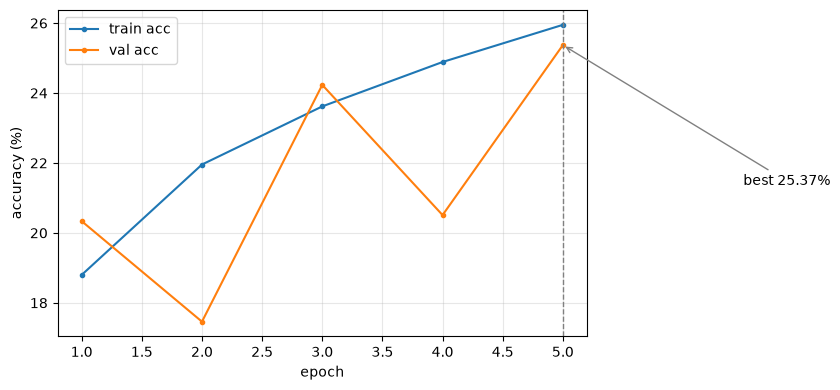

In [21]:
import matplotlib.pyplot as plt

hist = pd.read_csv(f'{CKPT_DIR}/history.csv')
best = hist.loc[hist['val_acc'].idxmax()]

plt.figure(figsize=(9, 4))
plt.plot(hist['epoch'], hist['train_acc'], marker='o', ms=3, label='train acc')
plt.plot(hist['epoch'], hist['val_acc'], marker='o', ms=3, label='val acc')
plt.axvline(best['epoch'], ls='--', c='gray', lw=1)
plt.annotate('best %.2f%%' % best['val_acc'],
             xy=(best['epoch'], best['val_acc']),
             xytext=(best['epoch'] + 1.5, best['val_acc'] - 4),
             arrowprops=dict(arrowstyle='->', color='gray'))
plt.xlabel('epoch'); plt.ylabel('accuracy (%)')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

# 4. Inference with Testing Data On-the-Fly

每題給的是同一位玩家的多局棋譜。做法是每局各自過模型取 softmax，再把機率平均起來
才 argmax —— 等於讓多局棋一起投票，比單局判斷穩定。

**Public 與 Private 兩份題目都要預測，串接成一份 800 列的 submission 上傳。**
缺任何一份的題目，該次提交無效。`question_id` 的 `pub_` / `priv_` 前綴要原樣照抄。

In [5]:
GPU_BATCH = 64
_infer_parser = SGFParseRankPrediction()


def sgf_to_features(sgf_content):
    """給 multiprocessing.Pool 用的頂層函式。"""
    feat, err = _infer_parser.features_from_sgf_content(sgf_content)
    return None if err is not None else feat


def predict(weights_path, out_path):
    net = GoRankResNet(num_classes=NUM_CLASSES)
    net.load_state_dict(torch.load(weights_path, map_location='cpu'))
    net.eval().to(DEVICE)

    rows = []
    with Pool(NPROC) as pool:
        # 兩份題目都要跑，結果串接成同一份 submission
        for split in ('public', 'private'):
            test = pd.read_csv(f'{TEST_DIR}/rank_prediction_test_{split}.csv')
            sgf_cols = [c for c in test.columns if c.startswith('sgf_')]
            t0 = time.time()

            for idx, r in test.iterrows():
                # num_games 之後的 sgf_ 欄位是空字串，要濾掉
                sgfs = [r[c] for c in sgf_cols
                        if pd.notna(r[c]) and str(r[c]).strip()]
                feats = [f for f in pool.map(sgf_to_features, sgfs) if f is not None]
                if not feats:
                    rows.append([r['question_id'], LEVELS[0]])
                    continue

                x = torch.from_numpy(np.stack(feats)).float()
                probs = []
                with torch.no_grad():
                    for i in range(0, len(x), GPU_BATCH):
                        out = net(x[i:i + GPU_BATCH].to(DEVICE))
                        probs.append(out.softmax(1).cpu().numpy())

                avg = np.concatenate(probs).mean(0)      # 同題多局的機率平均
                rows.append([r['question_id'], LEVELS[int(avg.argmax())]])
                if (idx + 1) % 100 == 0:
                    print('  %s %d/%d  %.0f 秒'
                          % (split, idx + 1, len(test), time.time() - t0), flush=True)
            print('  %s 完成 %d 題' % (split, len(test)), flush=True)

    sub = pd.DataFrame(rows, columns=['question_id', 'pred_rank'])
    sub.to_csv(out_path, index=False)
    print('寫出 %s（%d 列）' % (out_path, len(sub)))
    print('預測分布:', sub['pred_rank'].value_counts().to_dict())
    return sub

In [6]:
submission = predict(f'{CKPT_DIR}/best_model.pth', './submission_rank.csv')
submission.head()

  public 100/400  8 秒
  public 200/400  13 秒
  public 300/400  19 秒
  public 400/400  25 秒
  public 完成 400 題
  private 100/400  6 秒
  private 200/400  12 秒
  private 300/400  18 秒
  private 400/400  24 秒
  private 完成 400 題
寫出 ./submission_rank.csv（800 列）
預測分布: {'D': 251, '6D': 148, 'B': 99, '3D': 89, '5D': 60, '1D': 54, 'A': 44, '2D': 27, '4D': 15, 'C': 13}


,question_id,pred_rank
0,pub_q_0001,2D
1,pub_q_0002,D
2,pub_q_0003,1D
3,pub_q_0004,3D
4,pub_q_0005,B


In [7]:
def predict_logsum(weights_path, out_path):
    net = GoRankResNet(num_classes=NUM_CLASSES)
    net.load_state_dict(torch.load(weights_path, map_location='cpu'))
    net.eval().to(DEVICE)

    rows = []
    with Pool(NPROC) as pool:
        for split in ('public', 'private'):
            test = pd.read_csv(f'{TEST_DIR}/rank_prediction_test_{split}.csv')
            sgf_cols = [c for c in test.columns if c.startswith('sgf_')]

            for idx, r in test.iterrows():
                sgfs = [r[c] for c in sgf_cols
                        if pd.notna(r[c]) and str(r[c]).strip()]
                feats = [f for f in pool.map(sgf_to_features, sgfs) if f is not None]
                if not feats:
                    rows.append([r['question_id'], LEVELS[0]])
                    continue

                x = torch.from_numpy(np.stack(feats)).float()
                logps = []
                with torch.no_grad():
                    for i in range(0, len(x), GPU_BATCH):
                        out = net(x[i:i + GPU_BATCH].to(DEVICE))
                        logps.append(out.log_softmax(1).cpu().numpy())

                total = np.concatenate(logps).sum(0)
                rows.append([r['question_id'], LEVELS[int(total.argmax())]])
            print(split, 'done', len(test))

    sub = pd.DataFrame(rows, columns=['question_id', 'pred_rank'])
    sub.to_csv(out_path, index=False)
    print('rows:', len(sub))
    print(sub['pred_rank'].value_counts().to_dict())
    return sub

submission_logsum = predict_logsum(f'{CKPT_DIR}/best_model.pth', './submission_rank_logsum.csv')

public done 400
private done 400
rows: 800
{'D': 158, 'B': 127, '3D': 102, 'A': 93, '5D': 81, '1D': 70, '6D': 65, '2D': 39, '4D': 33, 'C': 32}


# End of the tutorial

棋力預測 tutorial 到此結束。照本 notebook 從頭跑完一次，在 Public 測試集上可以得到
**0.4631** 的分數。

Private 測試集的分數於競賽結束後才公布，所以這裡不列——排行榜上看得到的、
能拿來比較自己改動的，只有 Public 分數。

這個分數是在下列環境跑出來的：

| 項目 | 規格 |
|---|---|
| GPU | NVIDIA GeForce RTX 4090（24 GB，driver 535.288.01） |
| CPU | AMD EPYC-Genoa，8 核 |
| 記憶體 | 31 GB |
| OS | Ubuntu 22.04.5 LTS |
| 環境 | Python 3.10.12、PyTorch 2.6.0+cu124、CUDA 12.4 |

本 tutorial 僅供參考，本競賽對模型架構、特徵設計與訓練方式都沒有限制，
歡迎依需求修改與改進。祝你在棋力預測模型上一切順利！
